# 06. Árvore de Decisão para Análise de Sentimentos

Este notebook apresenta a implementação e avaliação de um modelo de **Árvore de Decisão** para a classificação de sentimentos nas avaliações do IMDB.

## Etapas
1. Importação das bibliotecas e módulos.
2. Carregamento do conjunto de dados com embeddings pré-computados.
3. Separação de features e variável alvo.
4. Divisão dos dados em treino e teste (estratificada).
5. Treinamento da Árvore de Decisão e ajuste de hiperparâmetros.
6. Avaliação do modelo (métricas e Matriz de Confusão).
7. Exemplo prático de predição.

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import plot_tree
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR / "src") not in sys.path:
    sys.path.append(str(ROOT_DIR / "src"))

from data.split import split_data
from models.decision_tree_v2 import carregar_dados, buscar_hiperparametros

In [3]:
DATA_PATH = ROOT_DIR / "data" / "processed" / "IMDB_menor_embeddings_v2.csv"

X, y = carregar_dados(DATA_PATH)

print(f"Matriz X: {X.shape}")
print(f"Vetor y: {y.shape}")

Matriz X: (2000, 384)
Vetor y: (2000,)


In [4]:
print("Distribuição das classes (0 = negativo, 1 = positivo):")
print(pd.Series(y).value_counts().sort_index())

Distribuição das classes (0 = negativo, 1 = positivo):
0     995
1    1005
Name: count, dtype: int64


In [5]:
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

for nome, conjunto in [("Treinamento", X_train), ("Validação", X_val), ("Teste", X_test)]:
    print(f"{nome}: {len(conjunto)} amostras ({len(conjunto) / len(X):.0%})")

Treinamento: 1400 amostras (70%)
Validação: 300 amostras (15%)
Teste: 300 amostras (15%)


In [6]:
best_dt, melhores_params, resultados_busca = buscar_hiperparametros(X_train, y_train, X_val, y_val)

print(f"Melhores parâmetros encontrados: {melhores_params}")
print(f"F1 macro na validação: {resultados_busca['val_f1_macro'].iloc[0]:.4f}")
resultados_busca.head(10)

Melhores parâmetros encontrados: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 10}
F1 macro na validação: 0.6431


,param_criterion,param_max_depth,param_min_samples_split,val_f1_macro
0,gini,NaN,10,0.643139
1,gini,10.0,2,0.642439
2,gini,5.0,2,0.638699
3,gini,5.0,5,0.638699
4,gini,5.0,10,0.638699
5,gini,NaN,2,0.629798
6,entropy,5.0,2,0.626600
7,entropy,5.0,5,0.626600
8,entropy,5.0,10,0.626600
9,gini,10.0,5,0.625602


In [7]:
y_pred = best_dt.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro')
rec = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

print("--- Métricas de Desempenho ---")
print(f"Acurácia:  {acc:.4f}")
print(f"Precisão:  {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

print("--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred))

--- Métricas de Desempenho ---
Acurácia:  0.6133
Precisão:  0.6135
Recall:    0.6131
F1-Score:  0.6129

--- Relatório de Classificação ---
              precision    recall  f1-score   support

           0       0.62      0.58      0.60       149
           1       0.61      0.64      0.63       151

    accuracy                           0.61       300
   macro avg       0.61      0.61      0.61       300
weighted avg       0.61      0.61      0.61       300



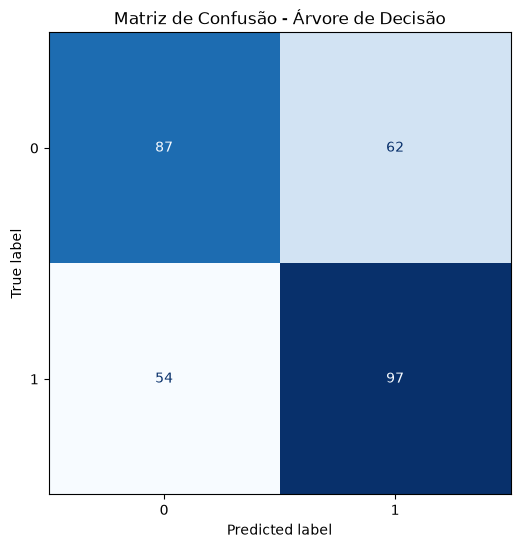

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
plt.title("Matriz de Confusão - Árvore de Decisão")
plt.show()

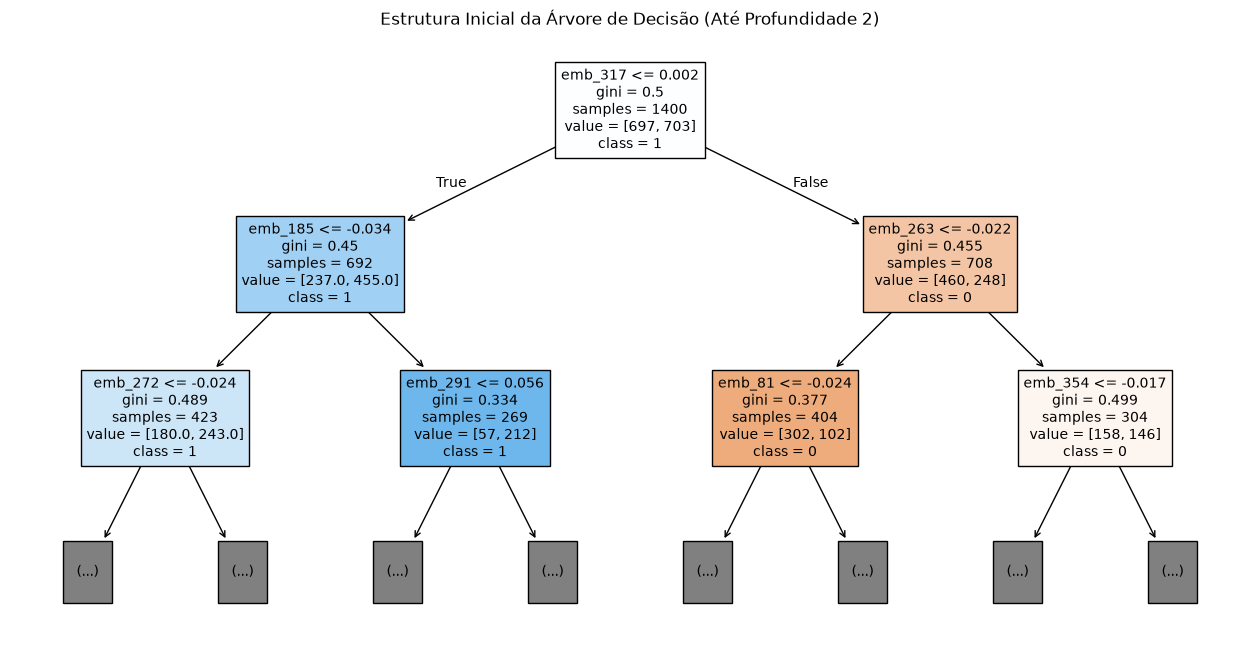

In [9]:
# gera a lista com os nomes das 384 features de embedding
feature_cols = [f"emb_{i}" for i in range(X.shape[1])]

# árvore de decisão
plt.figure(figsize=(16, 8))
plot_tree(
    best_dt, 
    max_depth=2, 
    feature_names=feature_cols, 
    class_names=[str(c) for c in np.unique(y)], 
    filled=True, 
    fontsize=10
)
plt.title("Estrutura Inicial da Árvore de Decisão (Até Profundidade 2)")
plt.show()

## Conclusão

- A Árvore de Decisão foi treinada e otimizada via `GridSearchCV`.
- Os hiperparâmetros como `max_depth` e `min_samples_split` garantiram o controle do overfit.
- As métricas calculadas serão consolidadas no notebook comparativo posterior (`07_comparacao_modelos.ipynb`).